# Comparing Structural and Reduced-Form Credit Risk Models
## Merton, VK (KMV), and Hull-White

This notebook runs the full pipeline:
1. Data acquisition & cleaning
2. Three credit risk models (Merton, VK, Hull-White)
3. Default discrimination evaluation (ROC/AUC, CAP/AR)
4. Visualization

In [1]:
import sys, os

# Ensure project root is on the path
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(".")), ""))
# If running from notebooks/, go up one level
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import config

print(f"Sample: {len(config.ALL_TICKERS)} firms ({len(config.NON_DEFAULT_TICKERS)} non-default, {len(config.DEFAULT_TICKERS)} default)")
print(f"Period: {config.START_DATE} to {config.END_DATE}")

Sample: 50 firms (40 non-default, 10 default)
Period: 2018-01-01 to 2023-12-31


In [3]:
%pip install fredapi

Note: you may need to restart the kernel to use updated packages.


## 1. Data Acquisition & Panel Construction

In [4]:
from data import build_panel

panel = build_panel()
print(f"Panel shape: {panel.shape}")
print(f"Default firms found: {panel[panel['default_label'] == 1]['ticker'].nunique()}")
print(f"Non-default firms found: {panel[panel['default_label'] == 0]['ticker'].nunique()}")
panel.head(10)

Panel shape: (104, 15)
Default firms found: 10
Non-default firms found: 40


,ticker,year,date,price,market_cap,equity_vol,total_debt,short_term_debt,long_term_debt,default_point,total_assets,risk_free_rate,default_label,leverage_ratio,log_market_cap
0,AAPL,2022,2022-12-30,127.879333,1.877414e+12,0.355644,1.324800e+11,2.111000e+10,9.895900e+10,7.058950e+10,3.527550e+11,0.028042,0,0.065914,28.260917
1,AAPL,2023,2023-12-29,190.550476,2.797498e+12,0.203714,1.110880e+11,1.580700e+10,9.528100e+10,6.344750e+10,3.525830e+11,0.050832,0,0.038193,28.659747
2,AMC,2022,2022-12-30,40.700001,2.371985e+10,1.190452,1.001960e+10,2.000000e+07,5.120800e+09,2.580400e+09,9.135600e+09,0.028042,1,0.296970,23.889578
3,AMC,2023,2023-12-29,6.120000,3.566719e+09,1.260062,9.142300e+09,2.510000e+07,4.552300e+09,2.301250e+09,9.009200e+09,0.050832,1,0.719355,21.994912
4,AMZN,2022,2022-12-30,84.000000,9.017334e+11,0.500371,1.401180e+11,7.296800e+10,6.715000e+10,1.065430e+11,4.626750e+11,0.028042,0,0.134489,27.527585
5,AMZN,2023,2023-12-29,151.940002,1.631064e+12,0.328860,1.356110e+11,7.729700e+10,5.831400e+10,1.064540e+11,5.278540e+11,0.050832,0,0.076761,28.120254
6,BA,2022,2022-12-30,190.490005,1.496955e+11,0.468986,5.727700e+10,5.125000e+09,5.167000e+10,3.096000e+10,1.371000e+11,0.028042,0,0.276737,25.731869
7,BA,2023,2023-12-29,260.660004,2.048381e+11,0.270180,5.260300e+10,5.127000e+09,4.692700e+10,2.859050e+10,1.370120e+11,0.050832,0,0.204330,26.045486
8,BAC,2022,2022-12-30,30.441689,2.184703e+11,0.322907,3.029140e+11,2.693200e+10,2.759820e+11,1.649230e+11,3.051375e+12,0.028042,0,0.580980,26.109916
9,BAC,2023,2023-12-29,31.910795,2.290136e+11,0.267532,3.343020e+11,3.209800e+10,3.022040e+11,1.832000e+11,3.180151e+12,0.050832,0,0.593454,26.157047


In [5]:
# Quick data summary
print("=== Panel Summary ===")
print(panel[['market_cap', 'total_debt', 'equity_vol', 'leverage_ratio']].describe().round(4))
print(f"\nMissing values:\n{panel.isnull().sum()}")

=== Panel Summary ===
         market_cap    total_debt  equity_vol  leverage_ratio
count  1.040000e+02  1.040000e+02    104.0000        104.0000
mean   2.646447e+11  6.311456e+10      0.4110          0.2508
std    4.740110e+11  8.920607e+10      0.2721          0.2251
min    3.989248e+08  4.663000e+06      0.1348          0.0002
25%    2.942143e+10  9.373250e+09      0.2370          0.0850
50%    1.332725e+11  3.658600e+10      0.3037          0.1743
75%    2.533784e+11  5.794800e+10      0.4632          0.3292
max    2.797498e+12  4.365370e+11      1.2601          0.8460

Missing values:
ticker             0
year               0
date               0
price              0
market_cap         0
equity_vol         0
total_debt         0
short_term_debt    1
long_term_debt     1
default_point      1
total_assets       3
risk_free_rate     0
default_label      0
leverage_ratio     0
log_market_cap     0
dtype: int64


## 2. Run Credit Risk Models

In [6]:
from models import run_merton, run_vk, run_hull_white

# Step 1: Merton model
print("Running Merton model...")
panel = run_merton(panel)
print(f"  Merton solved: {panel['merton_PD'].notna().sum()} / {len(panel)} rows")

# Step 2: VK/KMV model
print("Running VK model...")
panel = run_vk(panel)
print(f"  VK solved: {panel['vk_PD'].notna().sum()} / {len(panel)} rows")

# Step 3: Hull-White (logistic hazard)
print("Running Hull-White model...")
panel = run_hull_white(panel)
print(f"  HW solved: {panel['hw_PD'].notna().sum()} / {len(panel)} rows")

print("\nDone!")

Running Merton model...


VK iteration did not converge after 200 iterations (|ΔV| = 1.91e-06)


  Merton solved: 104 / 104 rows
Running VK model...


VK iteration did not converge after 200 iterations (|ΔV| = 3.81e-06)
VK iteration did not converge after 200 iterations (|ΔV| = nan)


  VK solved: 103 / 104 rows
Running Hull-White model...
  HW solved: 104 / 104 rows

Done!


## 3. Firm-Level Risk Table

In [7]:
from analysis import summary_table

risk_table = summary_table(panel)
print(f"Risk table: {len(risk_table)} firms")
print("\n--- Top 15 by Merton PD (highest risk) ---")
risk_table.head(15)

Risk table: 104 firms

--- Top 15 by Merton PD (highest risk) ---


,ticker,default_label,merton_DD,merton_PD,vk_DD,vk_PD,hw_PD
0,AMC,1,0.256353,0.398839,0.662999,0.253666,0.627378
1,AMC,1,0.921368,0.178429,1.645244,0.049960,0.584692
2,HTZ,1,1.846943,0.032378,2.144376,0.016001,0.609336
3,BYND,1,1.899943,0.028720,2.457193,0.007001,0.622483
4,TLRY,1,1.956571,0.025199,2.408206,0.008016,0.628349
5,UAL,0,1.995684,0.022984,2.324161,0.010058,0.565708
6,BYND,1,2.118317,0.017074,2.728537,0.003181,0.626697
7,PLUG,1,2.141279,0.016126,3.049191,0.001147,0.623688
8,SPCE,1,2.185774,0.014416,2.753156,0.002951,0.628380
9,HTZ,1,2.215205,0.013373,2.526696,0.005757,0.609925


## 4. Model Discrimination — ROC/AUC & CAP/AR

In [8]:
from analysis import compute_roc_auc, compute_cap_ar
from analysis.discrimination import model_comparison_report

y_true = panel["default_label"].values
scores = {
    "Merton": panel["merton_PD"].values,
    "VK":     panel["vk_PD"].values,
    "HW":     panel["hw_PD"].values,
}

auc_results = compute_roc_auc(y_true, scores)
ar_results = compute_cap_ar(y_true, scores)

print("=== Model Discrimination Results ===\n")
print(f"{'Model':<10} {'AUC':>8} {'AR':>8}")
print("-" * 28)
for model in ["Merton", "VK", "HW"]:
    auc = auc_results.get(model, float("nan"))
    ar = ar_results.get(model, float("nan"))
    print(f"{model:<10} {auc:>8.4f} {ar:>8.4f}")

print("\n" + model_comparison_report(panel))

=== Model Discrimination Results ===

Model           AUC       AR
----------------------------
Merton       0.9097   0.8193
VK           0.9237   0.8474
HW           0.9910   0.9820

  Model Discrimination Comparison Report

  Observations : 104
  Defaults     : 23
  Non-defaults : 81

------------------------------------------------------------
  Model         ROC-AUC   Accuracy Ratio
------------------------------------------------------------
  Merton         0.9097           0.8193
  VK             0.9237           0.8474
  HW             0.9910           0.9820
------------------------------------------------------------

  Best ROC-AUC       : HW (0.9910)
  Best Accuracy Ratio: HW (0.9820)



## 5. Visualization

In [9]:
from analysis import plot_roc_curves, plot_cap_curves, plot_dd_distribution, plot_pd_comparison

# ROC curves
plot_roc_curves(y_true, scores)
print("Saved: output/roc_curves.png")

# CAP curves
plot_cap_curves(y_true, scores)
print("Saved: output/cap_curves.png")

# DD distribution (default vs non-default)
plot_dd_distribution(panel)
print("Saved: output/dd_distribution.png")

# PD pairwise comparison
plot_pd_comparison(panel)
print("Saved: output/pd_comparison.png")

Saved: output/roc_curves.png
Saved: output/cap_curves.png
Saved: output/dd_distribution.png
Saved: output/pd_comparison.png



  output/roc_curves.png


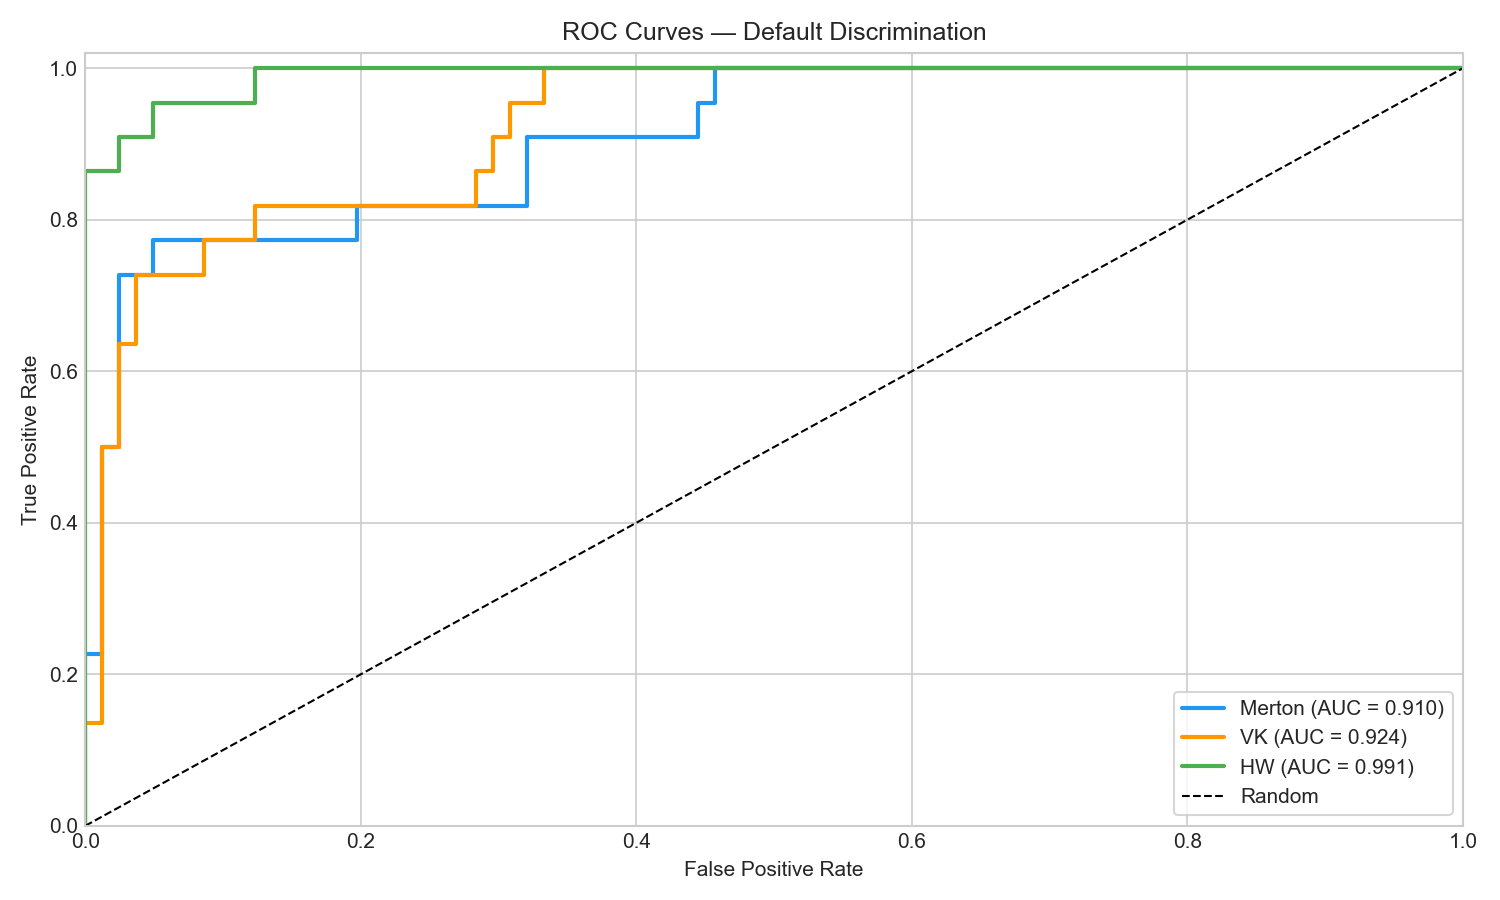


  output/cap_curves.png


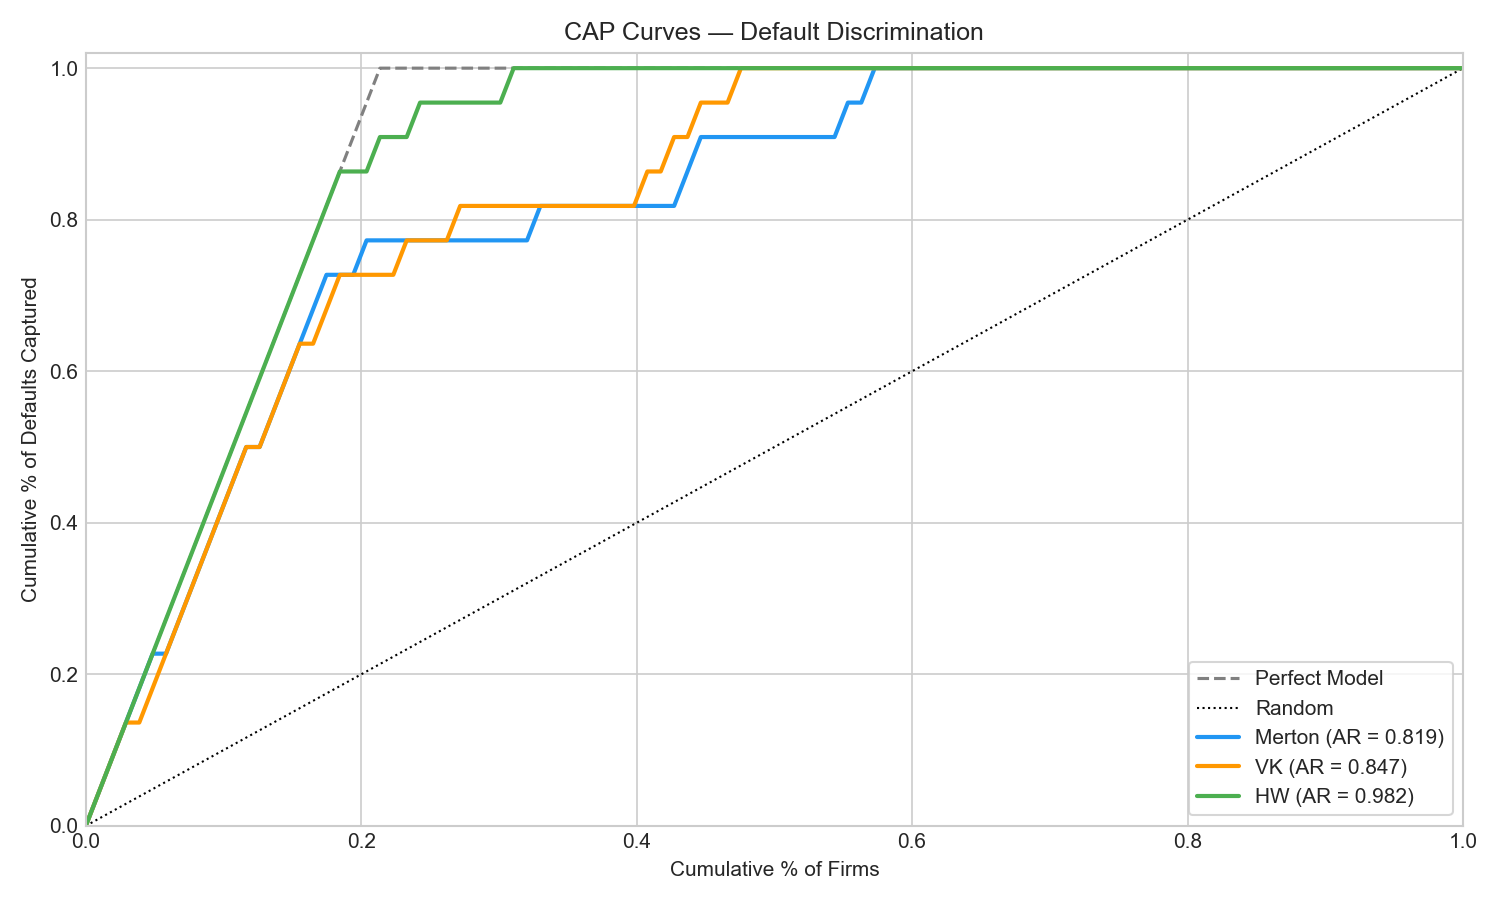


  output/dd_distribution.png


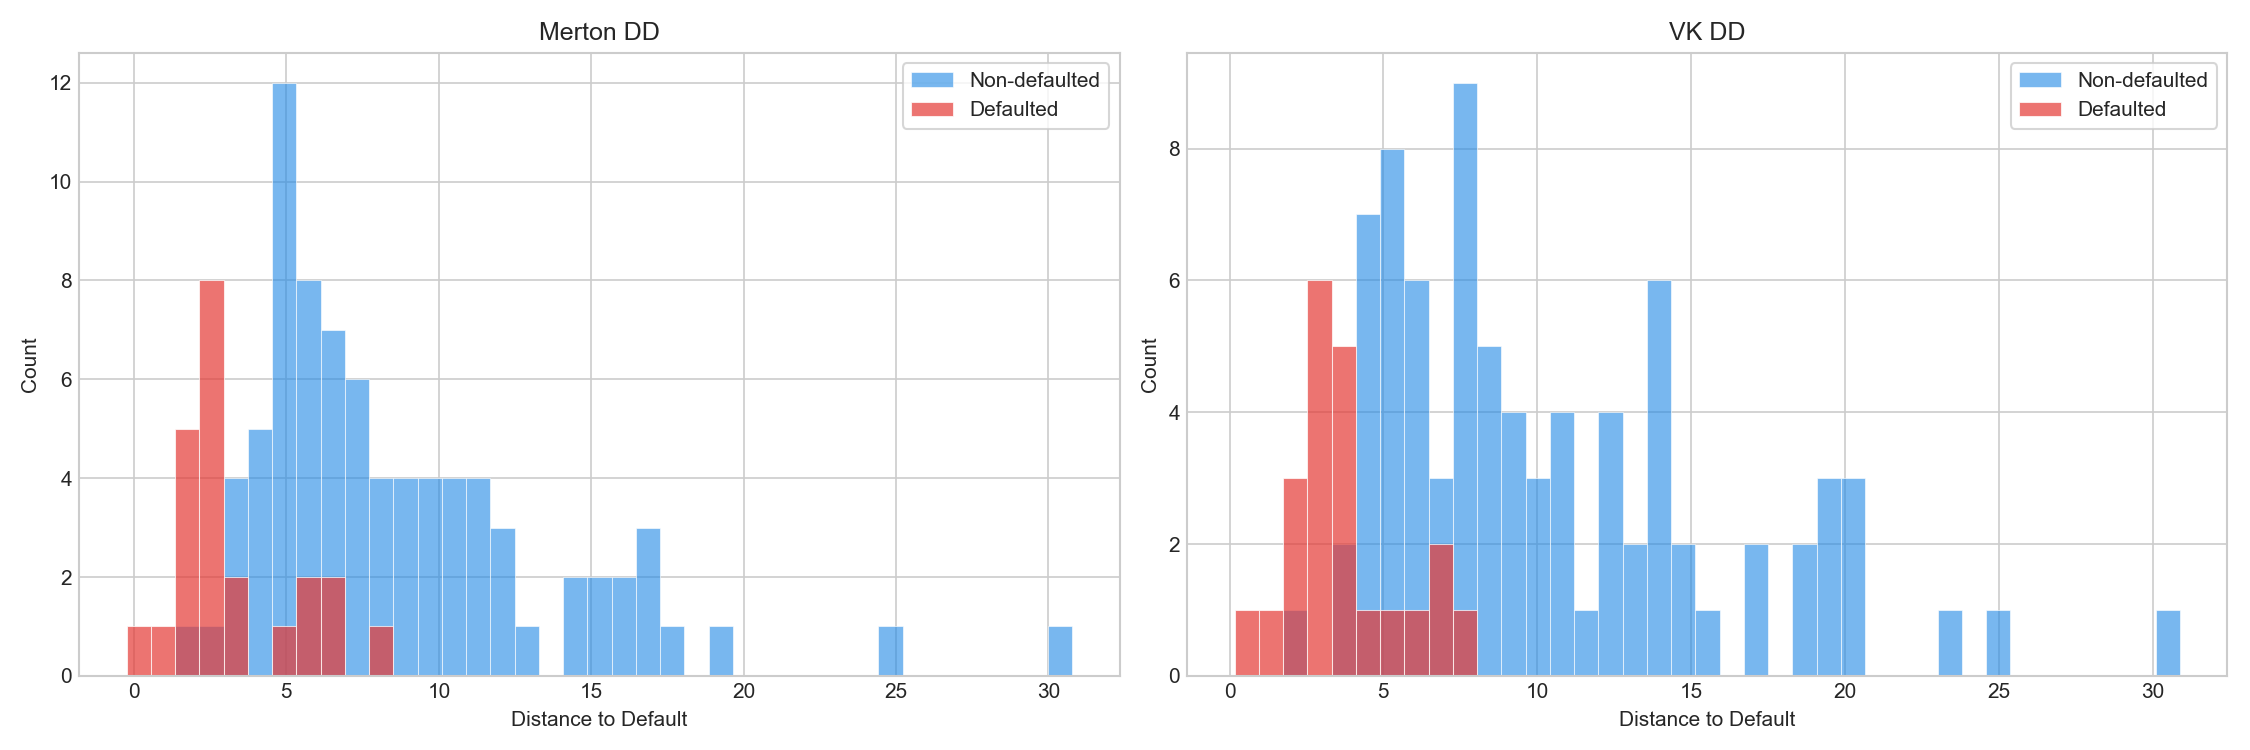


  output/pd_comparison.png


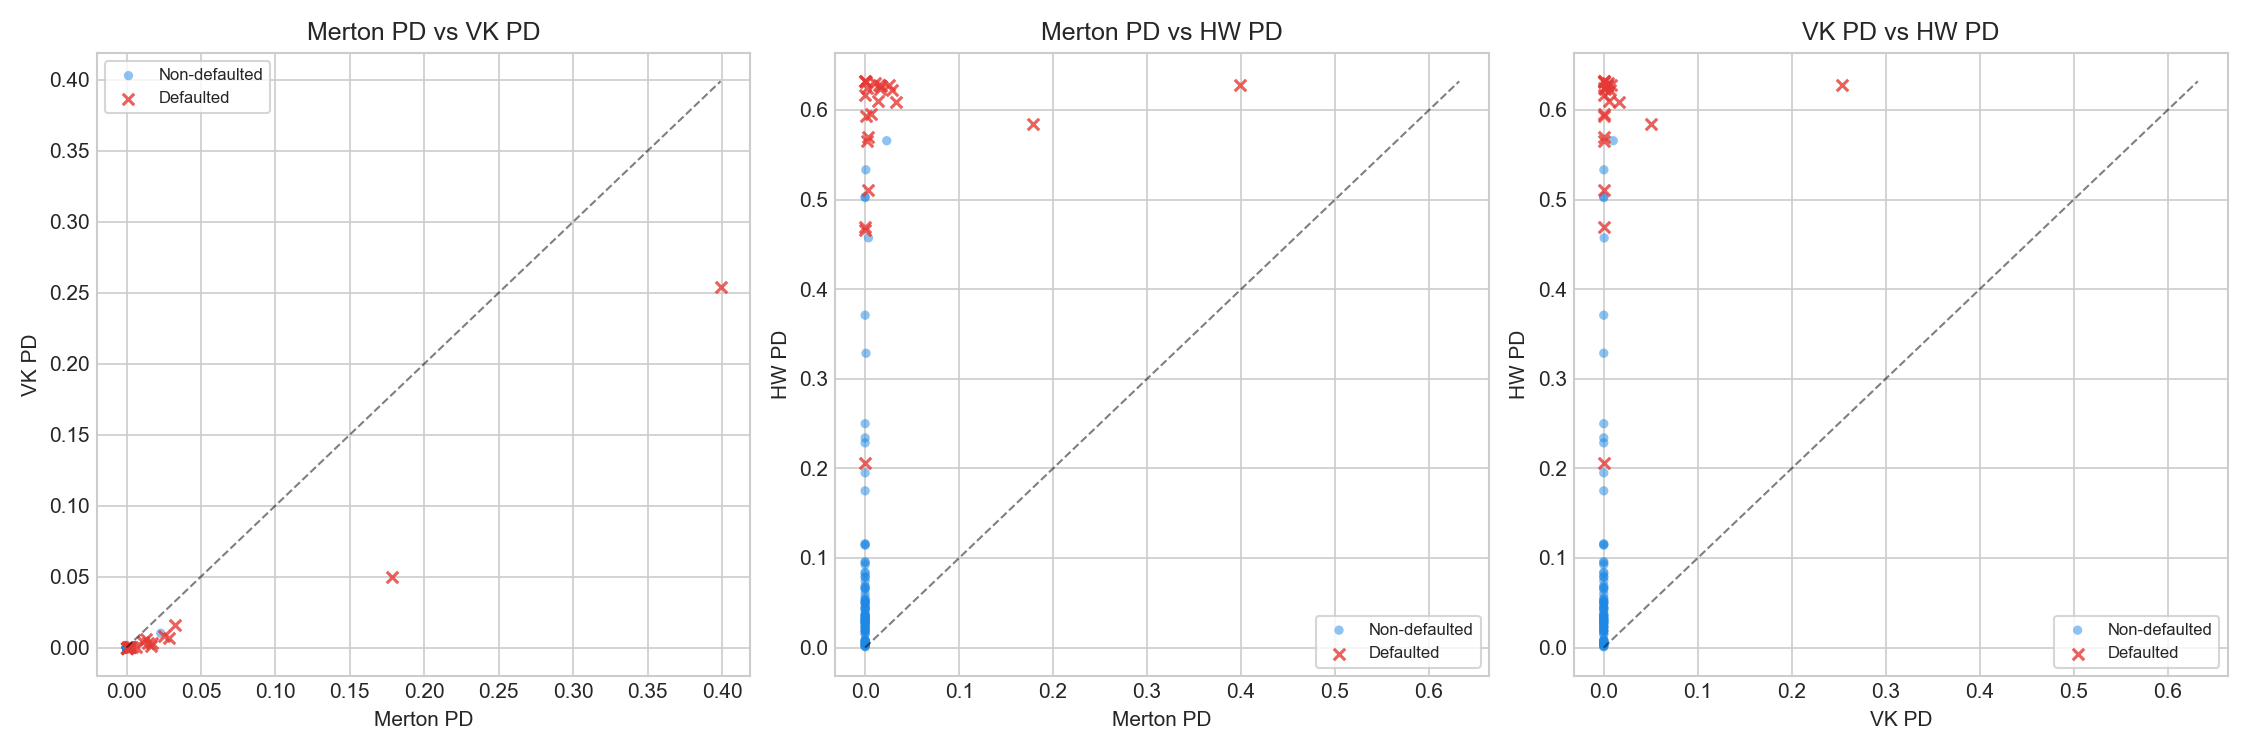

In [10]:
# Display the plots inline
from IPython.display import Image, display

for img in ["output/roc_curves.png", "output/cap_curves.png", 
            "output/dd_distribution.png", "output/pd_comparison.png"]:
    if os.path.exists(img):
        print(f"\n{'='*60}")
        print(f"  {img}")
        print(f"{'='*60}")
        display(Image(filename=img))

## 6. Export Results

In [11]:
# Save full results
panel.to_csv("output/panel_full_results.csv", index=False)
risk_table.to_csv("output/risk_summary_table.csv", index=False)

# Save discrimination metrics
metrics_df = pd.DataFrame({
    "Model": ["Merton", "VK", "HW"],
    "AUC": [auc_results.get(m, np.nan) for m in ["Merton", "VK", "HW"]],
    "AR":  [ar_results.get(m, np.nan) for m in ["Merton", "VK", "HW"]],
})
metrics_df.to_csv("output/discrimination_metrics.csv", index=False)

print("Exported:")
print("  - output/panel_full_results.csv")
print("  - output/risk_summary_table.csv")
print("  - output/discrimination_metrics.csv")
print("\nProject complete!")

Exported:
  - output/panel_full_results.csv
  - output/risk_summary_table.csv
  - output/discrimination_metrics.csv

Project complete!
